# AI-Based Car Fault Diagnosis — Analysis & Evaluation
**Project 5 · Sri Sashank Devarakonda (24B11AI085)**

Pipeline: *Sensor Feed → Preprocessing → ML Detection → Fault Check → Confidence Score → Dashboard Alert*

This notebook walks through the data, the model, and the evidence that it works — including where it **doesn't**.
Run `python -m car_fault.train` and `python -m car_fault.evaluate` first; this notebook reads their outputs.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from car_fault.config import SENSOR_NAMES, FAULTS
from car_fault.train import load_datasets, split
from car_fault.diagnose import get_engine
FIG = ROOT / "reports" / "figures"
metrics = json.loads((ROOT / "reports" / "metrics.json").read_text())
evaluation = json.loads((ROOT / "reports" / "evaluation.json").read_text())
pd.set_option("display.precision", 3)

## 1. The data
Public OBD-II datasets rarely include labelled faults, so readings are **simulated** across four driving modes (idle, city, highway, acceleration)
and each fault's physical signature is injected at a random intensity (25–100 %). Mild faults overlap healthy data on purpose.
A second dataset contains **two simultaneous faults** per row for the multi-fault detector.

In [2]:
df, multi = load_datasets()
print(f"Single-fault rows: {len(df):,} | Two-fault rows: {len(multi):,} | Sensors: {len(SENSOR_NAMES)}")
df.head()

Single-fault rows: 23,999 | Two-fault rows: 3,000 | Sensors: 15


,engine_rpm,vehicle_speed,engine_load,throttle_pos,coolant_temp,intake_air_temp,maf_rate,short_fuel_trim,long_fuel_trim,o2_voltage,battery_voltage,fuel_pressure,timing_advance,misfire_count,oil_pressure,driving_mode,fault
0,2246.244,34.846,52.545,8.516,86.977,20.296,18.935,7.154,-3.949,0.442,14.944,387.762,25.441,0.0,234.939,city,normal
1,4746.455,72.376,81.812,50.256,88.663,36.661,78.495,-1.761,-1.010,0.285,12.270,394.744,16.806,0.0,382.203,accel,battery_charging_fault
2,2177.682,109.354,50.327,23.086,85.461,31.200,17.451,0.689,7.862,0.237,14.342,296.689,29.742,2.0,277.497,highway,fuel_system_lean
3,688.874,0.000,19.263,3.915,89.202,39.274,1.012,2.573,8.861,0.217,13.971,365.952,14.606,0.0,180.013,idle,maf_sensor_fault
4,888.872,0.000,27.476,3.081,88.156,27.307,4.101,-0.644,3.137,0.275,13.985,373.614,15.043,1.0,243.207,idle,maf_sensor_fault


In [3]:
df[SENSOR_NAMES].describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
engine_rpm,2198.688,1054.278,385.854,6611.180
vehicle_speed,54.693,41.329,0.000,129.997
engine_load,42.721,18.702,8.000,100.000
throttle_pos,24.277,20.121,0.000,100.000
coolant_temp,89.592,13.008,30.013,131.506
intake_air_temp,30.804,10.571,4.822,63.936
maf_rate,18.940,17.307,0.744,129.045
short_fuel_trim,0.356,4.259,-18.763,16.548
long_fuel_trim,2.029,4.586,-15.236,24.201
o2_voltage,0.490,0.265,0.050,1.000


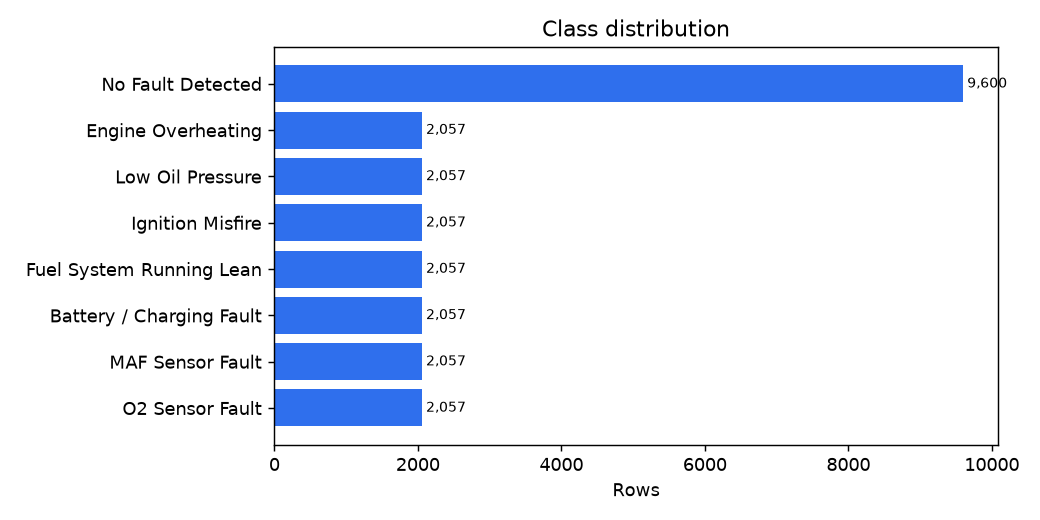

In [4]:
display(Image(FIG / "eda_class_distribution.png", width=600))

### Fault signatures
Each fault moves a different signal — the boxplots show why the problem is learnable, and also where classes overlap
(e.g. **MAF sensor fault vs. lean fuel system**: both push fuel trims positive).

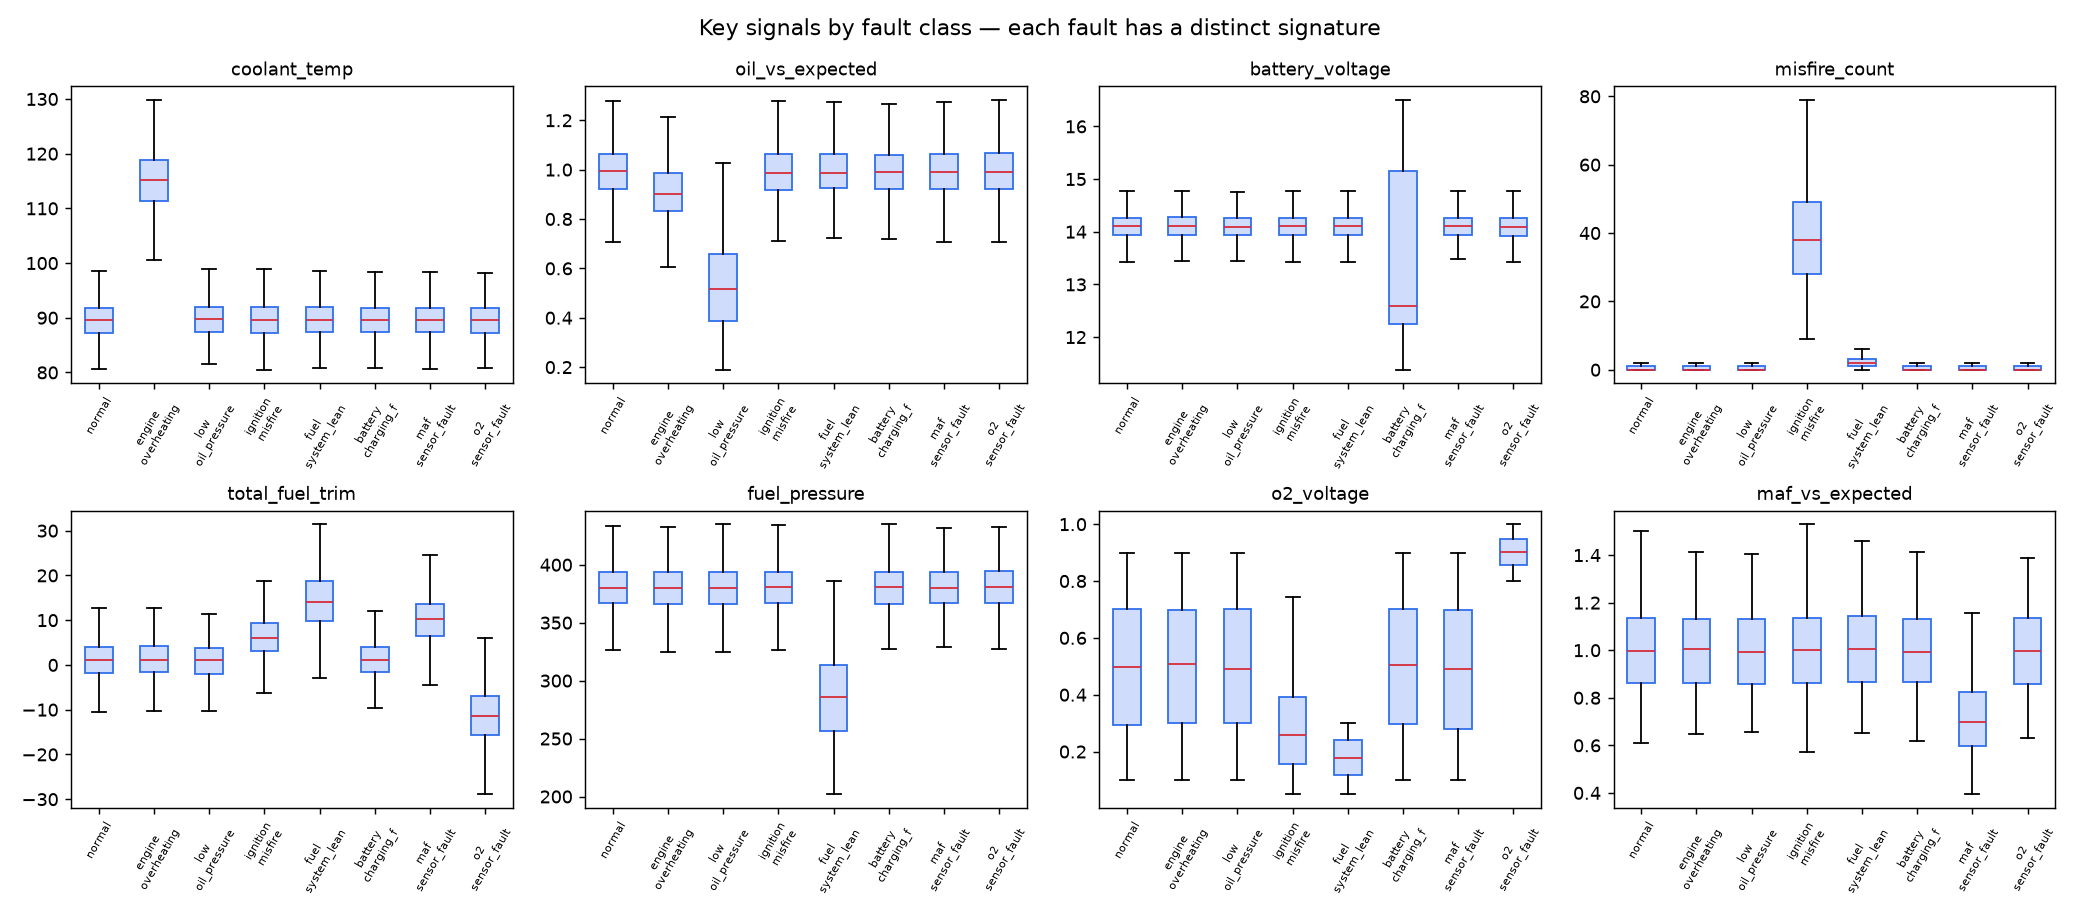

In [5]:
display(Image(FIG / "eda_sensor_boxplots.png"))

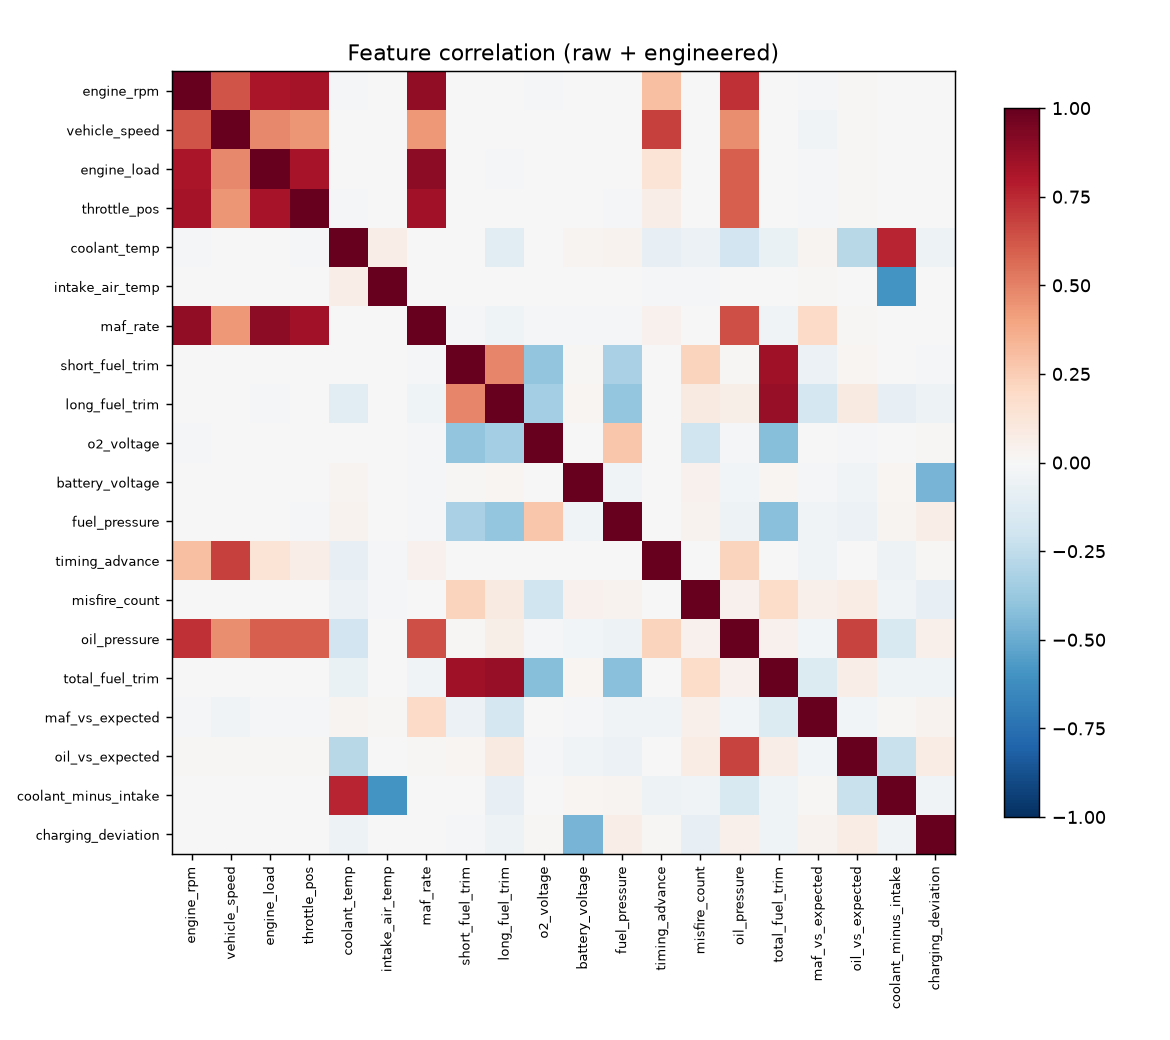

In [6]:
display(Image(FIG / "eda_correlation.png", width=650))

## 2. Model selection
Random Forest vs. Histogram Gradient Boosting, stratified 5-fold CV on the training split (80 %), scored by macro-F1.

In [7]:
pd.DataFrame(metrics["cv_macro_f1"]).T

,mean,std
random_forest,0.906,0.002
gradient_boosting,0.906,0.003


## 3. Held-out test performance (20 %, never seen in training)

In [8]:
pd.Series(metrics["test"]).to_frame("value")

,value
accuracy,0.931
macro_f1,0.936
weighted_f1,0.930
missed_fault_rate,0.069
false_alarm_rate,0.064


In [9]:
pd.DataFrame(metrics["per_class"]).T[["precision", "recall", "f1-score", "support"]]

,precision,recall,f1-score,support
normal,0.900,0.936,0.918,1920.0
engine_overheating,1.000,0.998,0.999,411.0
low_oil_pressure,0.937,0.908,0.922,412.0
ignition_misfire,1.000,1.000,1.000,412.0
fuel_system_lean,0.983,0.959,0.970,411.0
battery_charging_fault,0.993,0.995,0.994,411.0
maf_sensor_fault,0.807,0.752,0.778,411.0
o2_sensor_fault,0.938,0.879,0.907,412.0


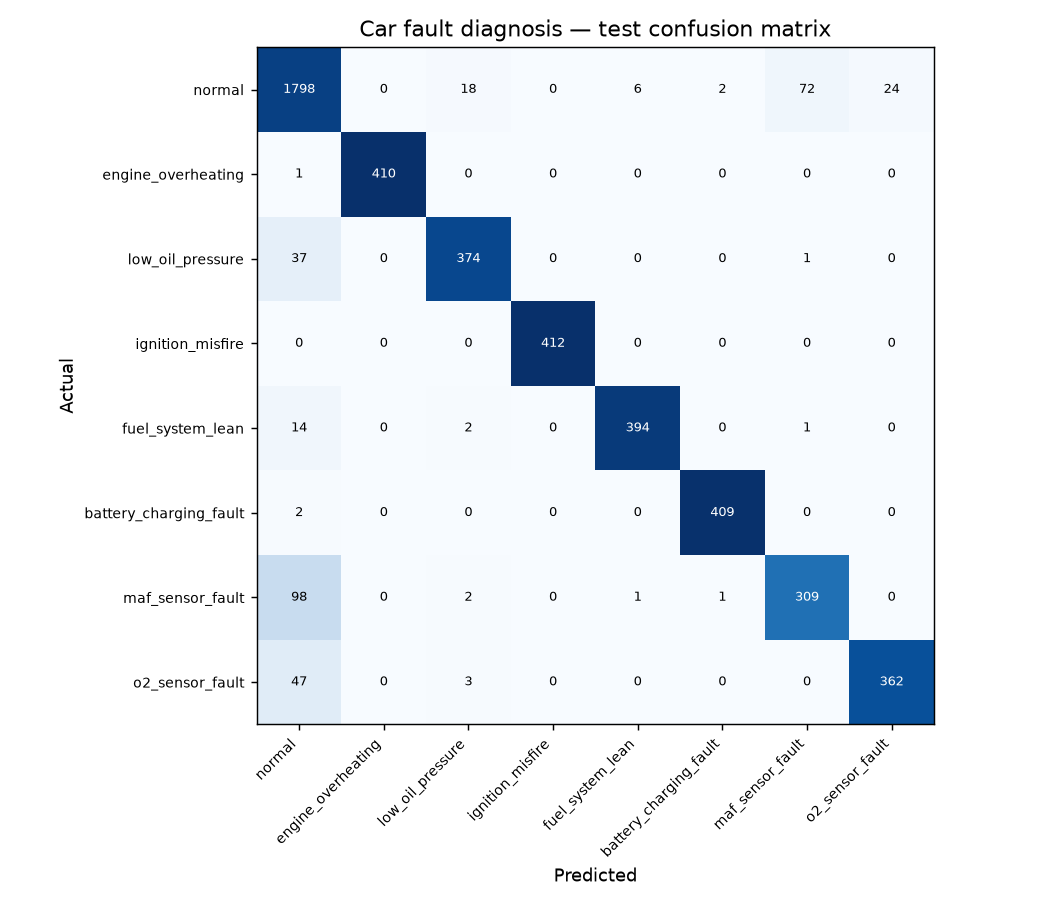

In [10]:
display(Image(ROOT / "reports" / "confusion_matrix.png", width=600))

In [11]:
print("ROC-AUC / PR-AUC per class (one-vs-rest):")
pd.DataFrame(evaluation["per_class_auc"]).T

ROC-AUC / PR-AUC per class (one-vs-rest):


,roc_auc,pr_auc
battery_charging_fault,1.000,1.000
engine_overheating,1.000,1.000
fuel_system_lean,0.998,0.989
ignition_misfire,1.000,1.000
low_oil_pressure,0.996,0.972
maf_sensor_fault,0.975,0.874
normal,0.980,0.961
o2_sensor_fault,0.997,0.974


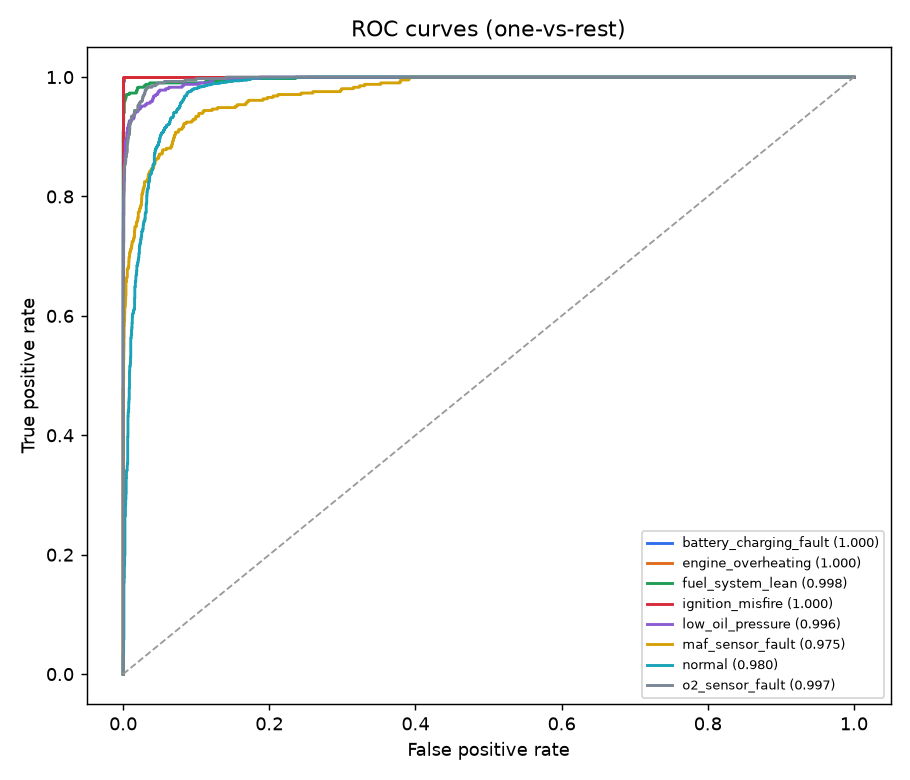

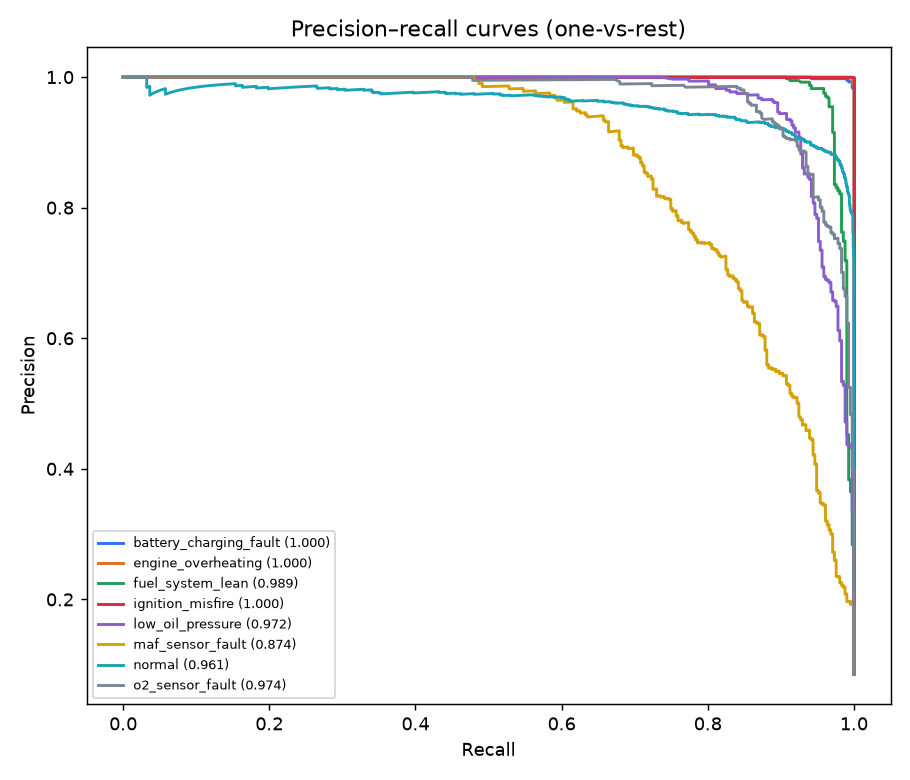

In [12]:
display(Image(FIG / "roc_curves.png", width=480)); display(Image(FIG / "pr_curves.png", width=480))

## 4. Confidence calibration
Random Forest vote shares are **not** probabilities. Isotonic calibration (5-fold, out-of-fold) makes "90 % confidence" mean right ~90 % of the time.
ECE = expected calibration error (lower is better).

In [13]:
cal = metrics["calibration"]
pd.DataFrame({k: {"ECE": v["ece"], "Brier": v["brier"]} for k, v in cal.items()}).T

,ECE,Brier
uncalibrated,0.080,0.137
calibrated,0.016,0.104


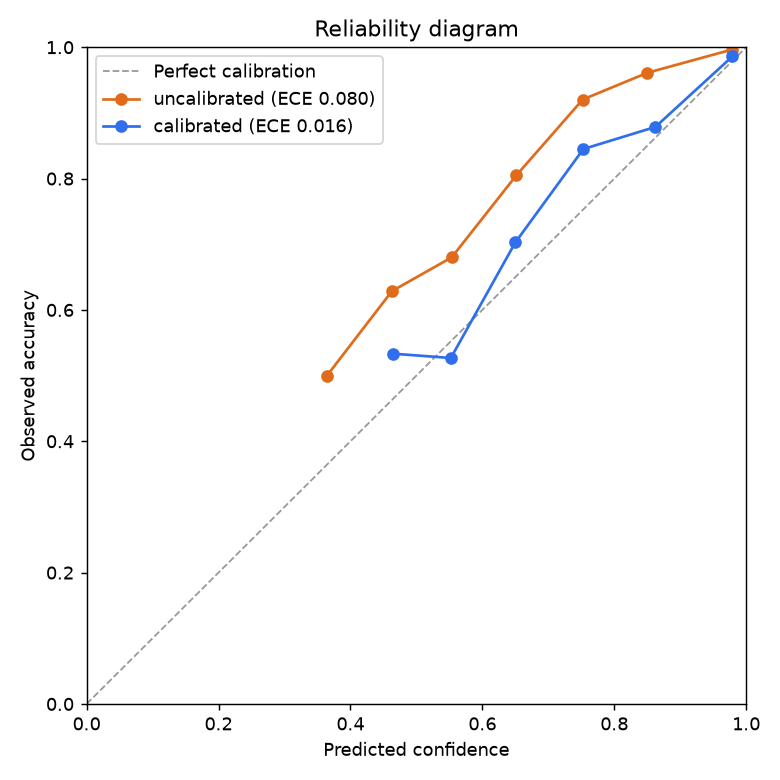

In [14]:
display(Image(FIG / "calibration_reliability.png", width=450))

## 5. Explainability (SHAP)
SHAP values show how much each feature pushed the model toward its prediction. Globally, each fault relies on the physically expected signal:

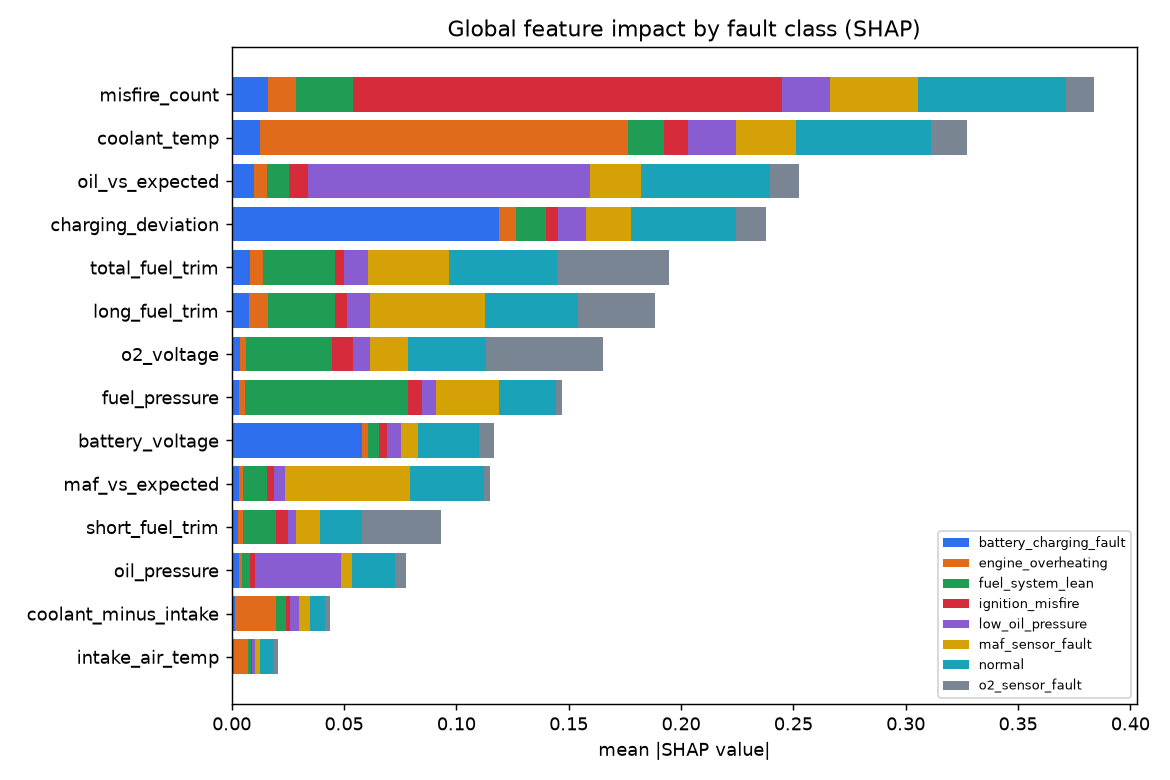

In [15]:
display(Image(FIG / "shap_importance.png", width=700))

### A single diagnosis, explained

In [16]:
from car_fault.data_generator import sample_reading
engine = get_engine()
r = engine.diagnose(sample_reading("fuel_system_lean", seed=4))
print(f"{r['fault_label']} | confidence {r['confidence']:.1%} | risk {r['risk_score']} ({r['risk_level']})")
contrib = pd.DataFrame(r["shap_contributions"])[["label", "value", "contribution"]]
colors = ["#2f6fed" if c > 0 else "#d62b3a" for c in contrib["contribution"][::-1]]
ax = contrib.iloc[::-1].plot.barh(x="label", y="contribution", legend=False, figsize=(7, 3.5), color=colors)
ax.set_title("Why the model chose this fault (SHAP)"); ax.set_xlabel("contribution toward prediction")
plt.tight_layout(); plt.show()
contrib

Fuel System Running Lean | confidence 100.0% | risk 65.0 (HIGH)


,label,value,contribution
0,Fuel rail pressure,235.265,0.308
1,Total fuel trim (short + long),19.833,0.129
2,Long-term fuel trim,11.875,0.118
3,O2 sensor voltage (B1S1),0.286,0.081
4,Misfires per 1000 rev,2.000,0.073
5,Short-term fuel trim,7.958,0.053


## 6. Robustness under distribution shift
A score on data from the same generator can be self-fulfilling. These tests change the data the model sees.

In [17]:
pd.DataFrame(evaluation["robustness"]).T

,accuracy,macro_f1,missed_fault_rate,false_alarm_rate
Clean test set,0.931,0.936,0.069,0.064
Unseen vehicles (new seed),0.932,0.936,0.070,0.058
Sensor noise +10% of sd,0.899,0.910,0.076,0.121
Sensor noise +25% of sd,0.856,0.875,0.081,0.199
Sensor drift (ageing),0.895,0.900,0.071,0.126
10% readings missing,0.861,0.865,0.156,0.071
Oil pressure not reported,0.858,0.811,0.192,0.058
Mild faults only,0.866,0.865,0.169,0.066


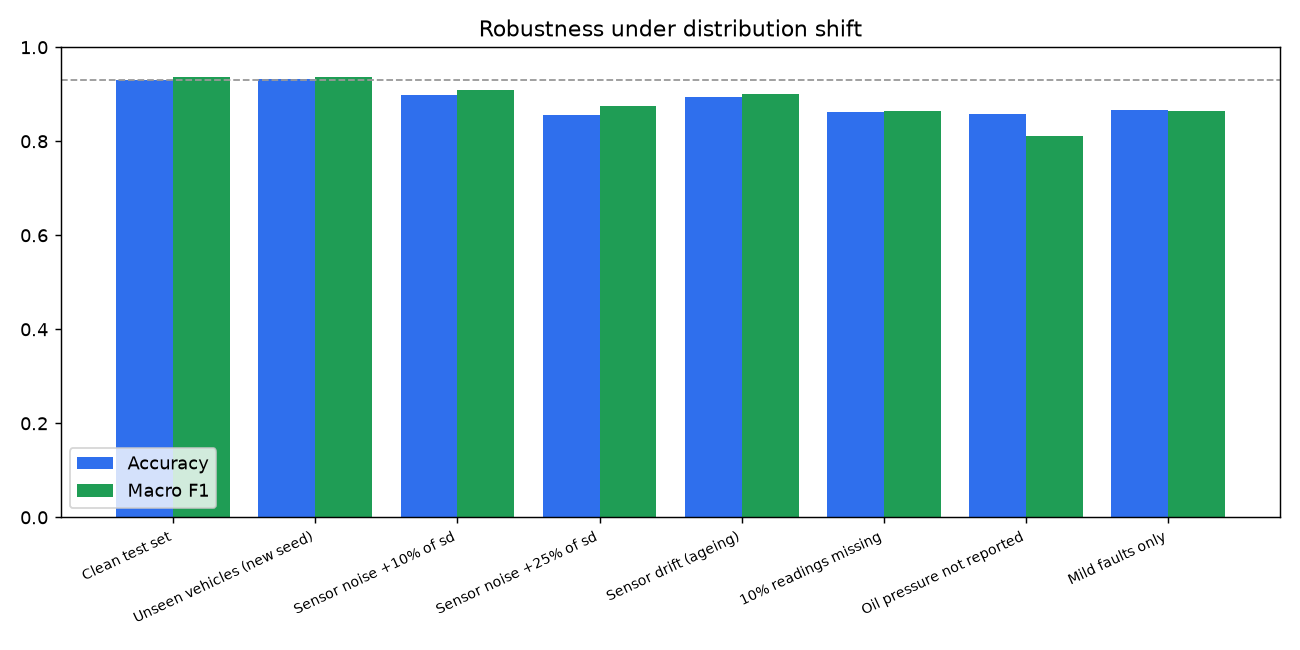

In [18]:
display(Image(FIG / "robustness.png", width=700))

**Reading the results honestly**
- *Unseen vehicles* ≈ clean test → the model is not memorising specific rows.
- Noise and sensor drift cost 3–8 points: graceful degradation, no collapse.
- *Oil pressure not reported* is the biggest drop: oil pressure is not a standard OBD-II PID, and without it low-oil faults are physically undetectable.
- *Mild faults only* raises the missed-fault rate — early-stage faults are genuinely hard; persistence (next section) helps catch them over time.

## 7. Alert persistence — fighting alert fatigue
A single reading alerts on ~5 % of healthy data. Requiring the same fault in **3 of the last 5** readings
(safety-critical faults alert immediately) cuts false alerts sharply at the cost of a ~3-reading delay.

In [19]:
pd.Series(evaluation["persistence"]["healthy"]).to_frame("value")

,value
raw_false_alert_per_reading,0.063
confirmed_false_alert_per_reading,0.006
vehicles_with_false_alert_raw,0.793
vehicles_with_false_alert_confirmed,0.107
readings_per_vehicle,20.000


In [20]:
pd.DataFrame(evaluation["persistence"]["faulty"]).T

,detected_within_10,mean_readings_to_alert,raw_reading_hit_rate
engine_overheating,1.000,1.000,1.000
low_oil_pressure,1.000,1.200,0.905
ignition_misfire,1.000,3.000,1.000
fuel_system_lean,1.000,3.175,0.955
battery_charging_fault,1.000,3.050,0.990
maf_sensor_fault,0.825,3.303,0.750
o2_sensor_fault,1.000,3.175,0.927


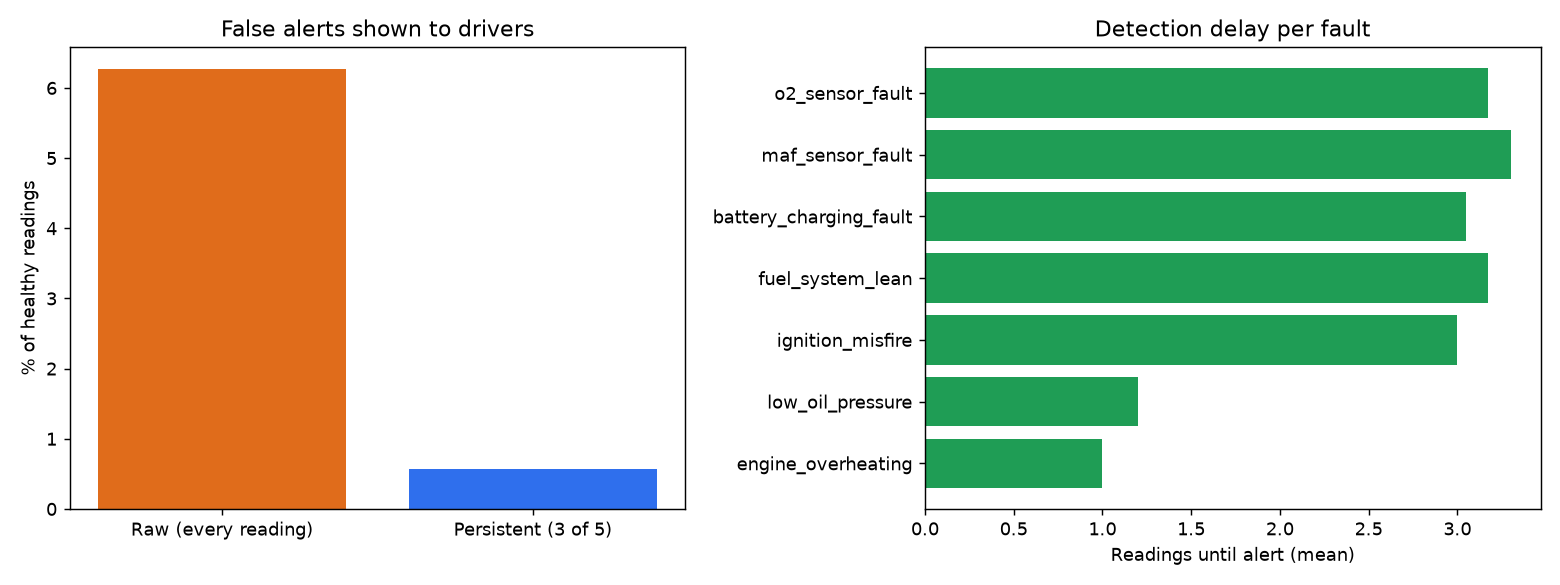

In [21]:
display(Image(FIG / "alert_persistence.png", width=800))

## 8. Multiple faults & unknown faults
- **Multi-fault detector** — multi-label Random Forest trained on single + two-fault data.
- **Novelty detector** — flags readings unlike anything in training. Isolation Forest was tried first and **failed** (it isolates on one random feature at a time, so a single extreme sensor barely registers); Local Outlier Factor works.

In [22]:
pd.DataFrame(metrics["multi_fault"]).T[["exact_match", "micro_precision", "micro_recall"]]

,exact_match,micro_precision,micro_recall
two_fault_test,0.917,1.0,0.958
single_fault_test,0.931,0.968,0.912


In [23]:
nov = metrics["novelty"]
print("Selected:", nov["selected"])
pd.DataFrame({k: {"known data flagged": v["known_test_flagged_rate"],
                  **{f"detects {u}": d for u, d in v["unseen_fault_detection_rate"].items()}}
              for k, v in nov["candidates"].items()}).T

Selected: local_outlier_factor


,known data flagged,detects unseen_coolant_sensor_open,detects unseen_rich_regulator
local_outlier_factor,0.008,1.000,1.000
isolation_forest,0.013,0.028,0.022


In [24]:
for scenario in ["engine_overheating+battery_charging_fault", "unseen_coolant_sensor_open", "unseen_rich_regulator"]:
    r = engine.diagnose(sample_reading(scenario, seed=1))
    print(f"{scenario:<42} -> {r['fault_label']:<32} risk {r['risk_level']:<8} "
          f"detected={[d['fault'] for d in r['detected_faults']]} novel={r['novelty']['is_novel']}")

engine_overheating+battery_charging_fault  -> Engine Overheating               risk CRITICAL detected=['engine_overheating', 'battery_charging_fault'] novel=False


unseen_coolant_sensor_open                 -> Unrecognised Abnormal Pattern    risk HIGH     detected=[] novel=True


unseen_rich_regulator                      -> Unrecognised Abnormal Pattern    risk HIGH     detected=[] novel=True


## 9. Real-world check — a real Toyota Etios (carOBD dataset)
Everything above uses data from my own simulator. To test a real car, I use the [carOBD dataset](https://github.com/eron93br/carOBD)
(2014 Toyota Etios, 1 Hz, normal driving, **no fault labels**). It logs 10 of our 15 sensors.

Trips are split **by trip**: 24 trips are used for training, and 11 are held out and never seen. Run `python -m car_fault.real_data --download` once to fetch the data.

In [25]:
v1 = json.loads((ROOT / "reports" / "real_data_evaluation_v1.json").read_text())
v2 = json.loads((ROOT / "reports" / "real_data_evaluation.json").read_text())
keys = ["raw_alert_rate", "confirmed_alert_rate", "trips_with_confirmed_alert", "novel_rate"]
pd.DataFrame({"v1: synthetic only": {k: v1["healthy_heldout"][k] for k in keys},
              "v2: + real data": {k: v2["healthy_heldout"][k] for k in keys}})

,v1: synthetic only,v2: + real data
raw_alert_rate,0.744,0.019
confirmed_alert_rate,0.565,0.000
trips_with_confirmed_alert,1.000,0.000
novel_rate,0.743,0.009


**v1 failed on the real car.** It raised a fault on 74 % of healthy readings, and every trip alerted. There were two causes:
1. *Missing sensors* were filled with training averages that didn't match the car's actual RPM and load, which broke the physics features.
2. *The simulator was wrong*: the real car has a hotter intake, much less ignition advance, and a lower charging voltage.

**v2 changes:**
- **Context-aware imputation.** Learned on healthy data: a missing sensor is filled with what a healthy car reads at this RPM, load, throttle and speed. The same learned expectations replace the generator's hard-coded constants in the physics features.
- **Real healthy driving in training**, with **fault signatures injected onto real readings** (semi-synthetic data).
- **Training with blanked sensors**, so the model learns to judge cars that don't report every PID.
- **Enabling conditions**, like real OBD-II monitors: no charging verdict in the first 60 s after start, and no fuel-trim verdict in the first 3 minutes.
- **Longer persistence for weak or slow faults**: 30 s for unknown patterns, 60 s for charging and fuel-trim faults.

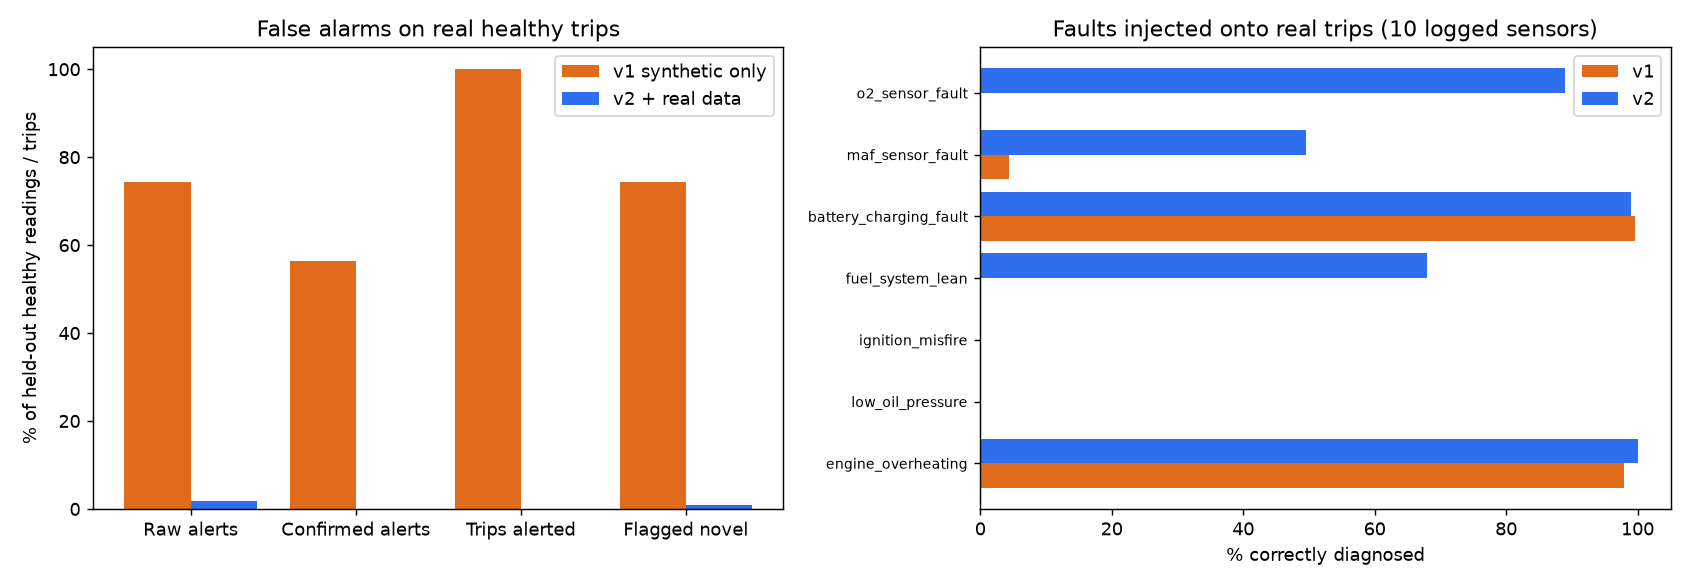

In [26]:
display(Image(FIG / "real_data_before_after.png"))

In [27]:
det = {m: {f: v["recall"] for f, v in d.items()} for m, d in v2["injected_fault_detection"].items()}
pd.DataFrame(det).rename(columns={"as_logged": "only the 10 logged sensors", "all_sensors": "all 15 sensors"})

,only the 10 logged sensors,all 15 sensors
engine_overheating,1.000,0.998
low_oil_pressure,0.000,0.888
ignition_misfire,0.000,1.000
fuel_system_lean,0.680,0.956
battery_charging_fault,0.990,0.988
maf_sensor_fault,0.496,0.852
o2_sensor_fault,0.890,0.962


**Reading the results honestly**
- On the 11 held-out real trips (about 9.8 hours of driving), confirmed false alerts fell from **56 % to 0 %**.
- With only the 10 sensors this car logs, **low oil pressure and misfires cannot be detected**, because their evidence lives in sensors the car doesn't report. If those sensors were available, they would be detected (right column).
- **Caveat:** I chose the enabling and duration rules after inspecting false alerts on these held-out trips, so 0 % is optimistic. A clean check needs trips that were never looked at.
- The injected faults are still simulated. **No publicly available dataset labels real faults**, so real fault *detection* remains unproven.

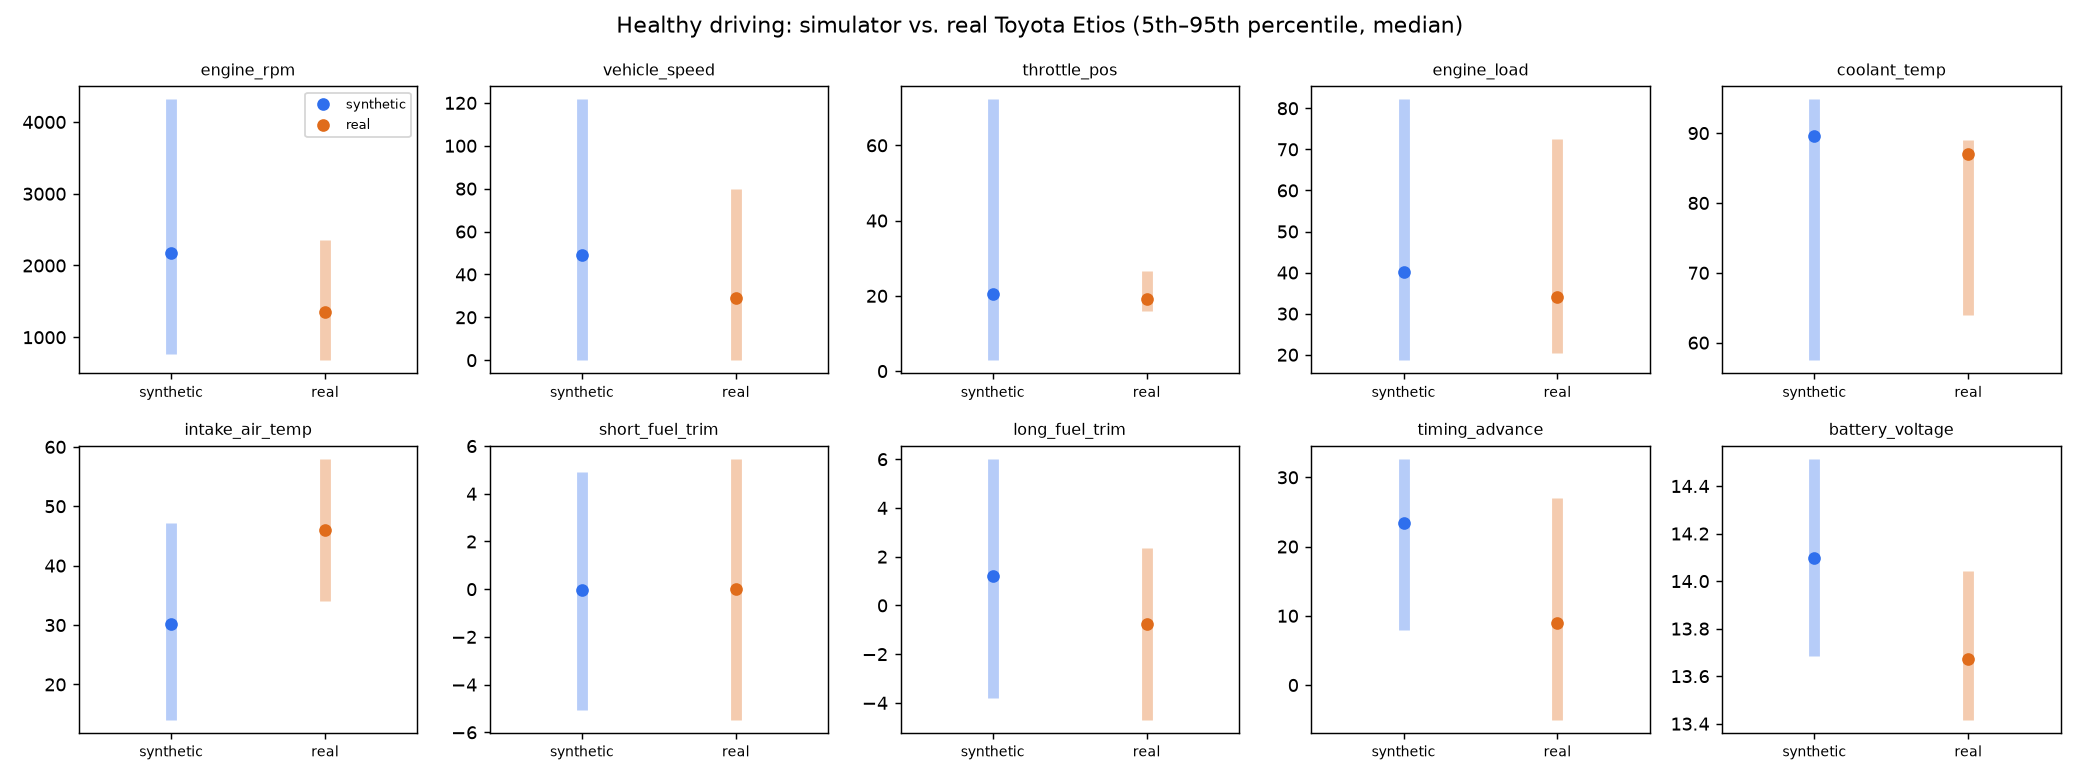

In [28]:
display(Image(FIG / "real_vs_synthetic_ranges.png"))

### Final test on never-seen trips
Because the alert rules were tuned on the 11 held-out trips, the honest check is **57 more trips (36.3 h)** that played no part in training or tuning. The model was run on them once, with no changes afterwards.

In [29]:
fresh = json.loads((ROOT / "reports" / "real_data_fresh_test.json").read_text())
h = fresh["healthy_heldout"]
pd.Series({"trips": h["trips"], "hours": round(fresh["hours"], 1), "raw alert rate": h["raw_alert_rate"],
           "confirmed alert rate": h["confirmed_alert_rate"], "trips with a confirmed alert": h["trips_with_confirmed_alert"]}).to_frame("never-seen trips")

,never-seen trips
trips,5.700e+01
hours,3.630e+01
raw alert rate,6.012e-02
confirmed alert rate,7.645e-05
trips with a confirmed alert,1.754e-02


Raw false faults are higher than on the tuning trips (6 % vs. 1.9 %), so the model alone is less clean on new driving. The persistence and enabling rules still hold: **1 of 57 trips** got a confirmed false alert, about one alert in 36 hours of real driving.

## 10. Limitations & future scope
- **One real car.** Real healthy data comes from a single 2014 Toyota Etios; other makes will differ. Faults are still injected signatures, not real failures, and no labelled real fault data is publicly available.
- **Rules tuned on held-out trips.** The enabling and duration rules were chosen while looking at the held-out real trips, so the 0 % on those trips is optimistic; on 57 never-seen trips, 1 trip got a confirmed false alert.
- **Snapshot model.** Each reading is classified alone; persistence adds temporal smoothing, but sequence models (rolling-window features, LSTM) could detect slowly developing faults earlier.
- **Two-fault combinations only**, from a fixed list of compatible pairs.
- **Novelty detection** is tested on two unseen faults; subtler unknown faults may look normal.
- **No live OBD-II adapter** yet — the dashboard uses a simulated feed through the same API a real ELM327 bridge would call.